# Mall Customer Segmentation - Experimenting K-means techniques with and without PCA


## Importing the dependencies

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [35]:
df=pd.read_csv("Mall_Customers.csv")

## Data Analysis and Pre-processing

In [36]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [69]:
df.describe()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Cluster1
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,0.440000,38.850000,60.560000,50.200000,1.400000,2.095000
std,57.879185,0.497633,13.969007,26.264721,25.823522,1.449311,1.643007
min,1.000000,0.000000,18.000000,15.000000,1.000000,0.000000,0.000000
25%,50.750000,0.000000,28.750000,41.500000,34.750000,0.000000,1.000000
50%,100.500000,0.000000,36.000000,61.500000,50.000000,1.000000,2.000000
75%,150.250000,1.000000,49.000000,78.000000,73.000000,3.000000,3.000000
max,200.000000,1.000000,70.000000,137.000000,99.000000,4.000000,5.000000


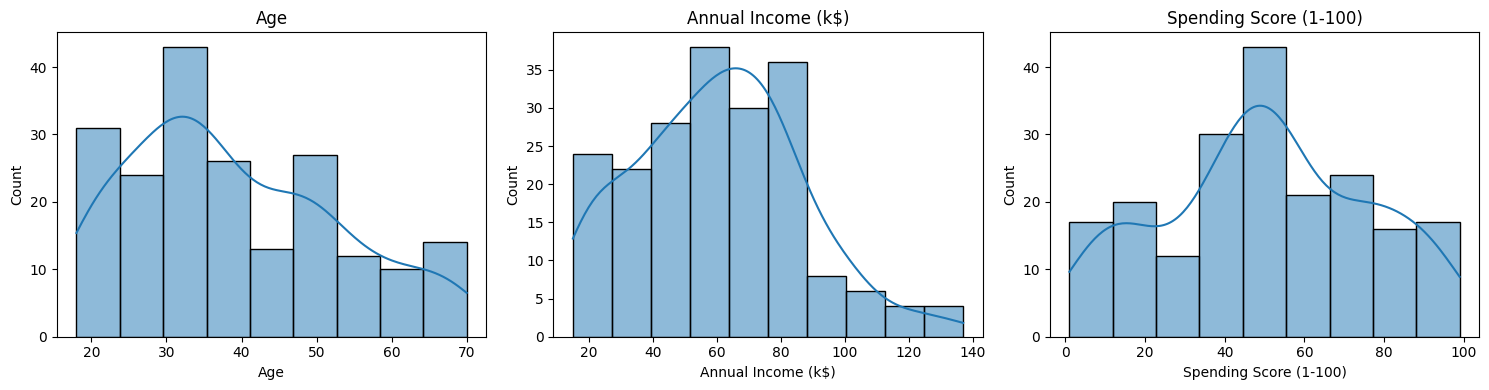

In [37]:
fig,axes=plt.subplots(1,3,figsize=(15,4))  #creates subplots with 1 row and 3 columns
# axes is the single figures within the subplot, and fig is the combined figure
for ax,col in zip(axes,['Age','Annual Income (k$)', 'Spending Score (1-100)']):
    sns.histplot(df[col],kde=True,ax=ax) 
    #kde=True ensures there is a smooth probability density curve
    #ax=ax ensures the plot is made on the selected subplot
    ax.set_title(col)
plt.tight_layout()
plt.show()

C:\Users\mahas\AppData\Local\Temp\ipykernel_26384\3846394453.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


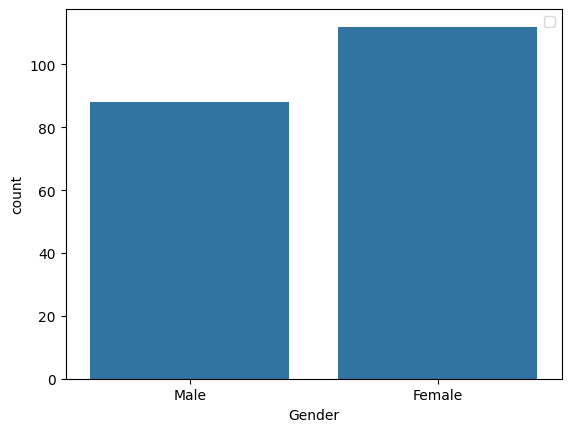

In [38]:
sns.countplot(x='Gender',data=df)
plt.legend()
plt.show()

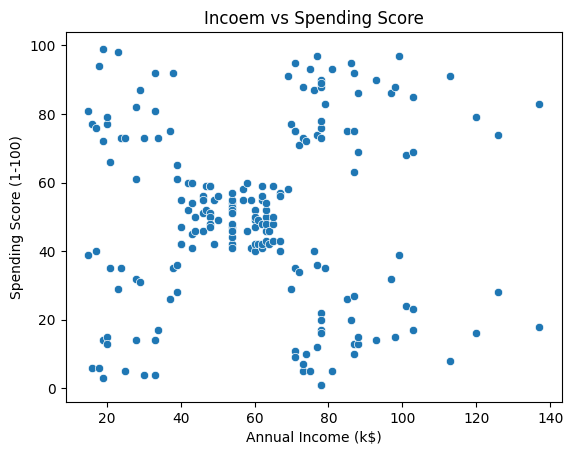

In [ ]:
sns.scatterplot(x='Annual Income (k$)',y='Spending Score (1-100)',data=df)
plt.title('Income vs Spending Score')
plt.show()

In [40]:
df.isnull().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [41]:
df.duplicated().sum()

np.int64(0)

In [42]:
df.shape

(200, 5)

In [43]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 8.9 KB


In [44]:
lb=LabelEncoder()
df['Gender']=lb.fit_transform(df['Gender'])

In [45]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


## 1. Two feature approach

- Annual Income (k$) and Spending Score (1-100) features were selected
- These features were scaled
- Best k value is chosen using Elbow Method and Silhouette scores based on the visualizaton
- KMeans model is fitted with the best k value
- The cluster visualization is made directly without using PCA since we have considered only 2 features
- Profile insights were created based on the clustering

### 1.1 Feature selection and Scaling

In [46]:
x=df.iloc[:,[3,4]].values

In [47]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

### 1.2 Elbow Method and Silhouette Score

In [48]:
wcss=[]
sil_scores=[]
k_range=range(2,11)

for k in k_range:
    #we repeatedly initialize the initial centroids and cluster the groups upto n_init times 
    # and finally choose the best one
    km=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    km.fit(x_scaled)
    wcss.append(km.inertia_)  #km.inertia_ returns the wcss of that specific clusters
    sil_scores.append(silhouette_score(x_scaled,km.labels_))



### 1.3 Plot for Elbow method and Silhouette score 

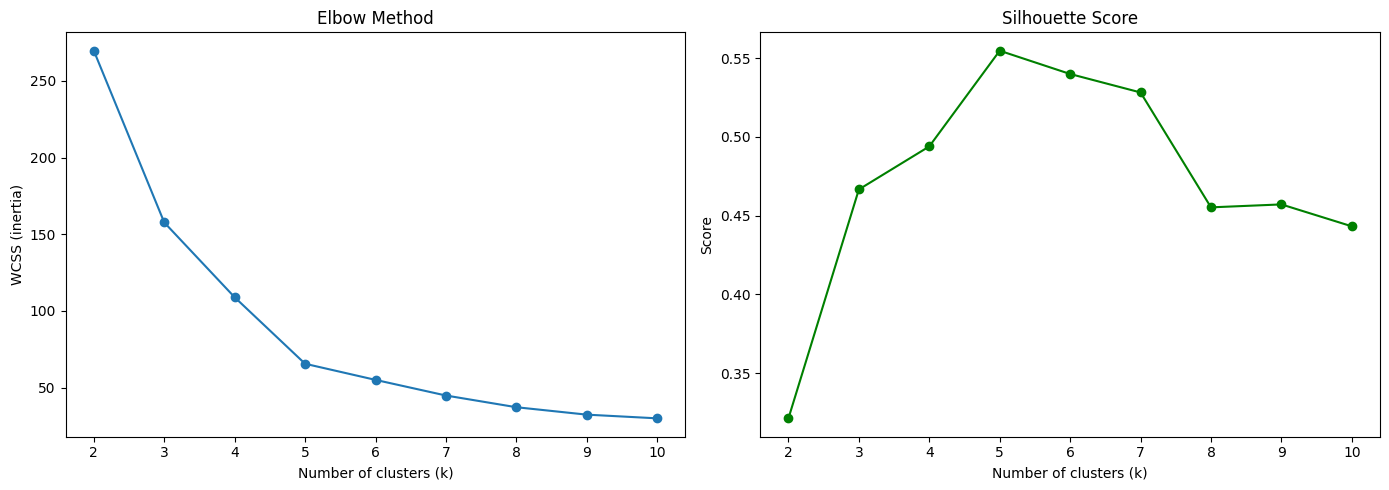

In [49]:
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].plot(list(k_range),wcss,marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('WCSS (inertia)')

axes[1].plot(list(k_range),sil_scores,marker='o',color='green')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()


In [50]:
for k,s in zip(k_range,sil_scores):
    print(f'k={k} : silhouette score={s:.4f}')

k=2 : silhouette score=0.3213
k=3 : silhouette score=0.4666
k=4 : silhouette score=0.4939
k=5 : silhouette score=0.5547
k=6 : silhouette score=0.5399
k=7 : silhouette score=0.5281
k=8 : silhouette score=0.4552
k=9 : silhouette score=0.4571
k=10 : silhouette score=0.4432


- 5 is chosen as best k value based on the wcss and silhouette score plots

### 1.4 Fitting the model with k=5

In [51]:
kmeans=KMeans(n_clusters=5,init='k-means++',n_init=10,random_state=42)
df['Cluster']=kmeans.fit_predict(x_scaled)
#fit_predict returns labels from range 0 to k-1

In [52]:
#silhouette_score returns values from -1 to +1
# silhouette_score(features, labels)
print('Silhouette Score : ',silhouette_score(x_scaled,df['Cluster']))
print(df['Cluster'].value_counts().sort_index())

Silhouette Score :  0.5546571631111091
Cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


### 1.5 Visualizaton of the clusters

##### While plotting the centroids, we have to take inverse transform to make sure the centroids are in the original scale

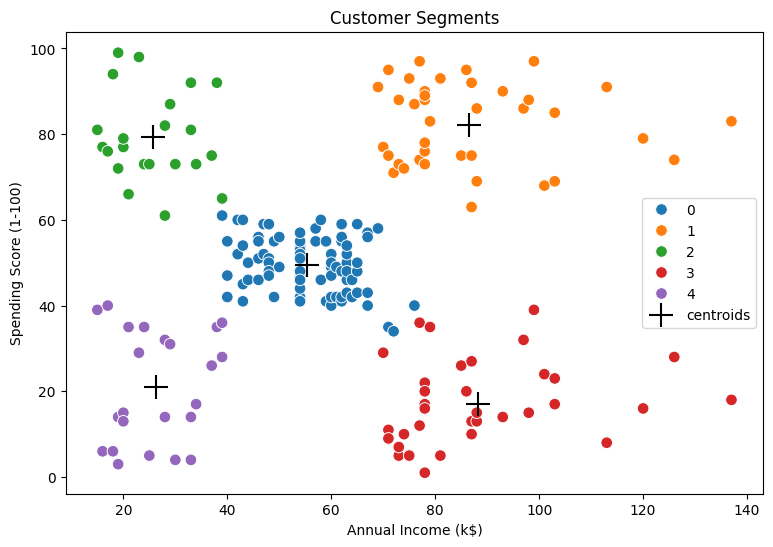

In [53]:
centroids=scaler.inverse_transform(kmeans.cluster_centers_)

plt.figure(figsize=(9,6))
sns.scatterplot(
    x='Annual Income (k$)', y='Spending Score (1-100)',
    hue='Cluster', palette='tab10', data=df,s=70
)
plt.scatter(centroids[:,0],centroids[:,1],s=300, c='black',marker='+',label='centroids')
plt.title("Customer Segments")
plt.legend()
plt.show()

### 1.6 Profile insights

In [70]:
profile=df.groupby('Cluster').agg(customers=('CustomerID','count'),
                                  avg_age=('Age','mean'),
                                  avg_income=('Annual Income (k$)','mean'),
                                  avg_spending=('Spending Score (1-100)','mean')

                                  ).round(1)
profile

,customers,avg_age,avg_income,avg_spending
Cluster,,,,
0,81,42.7,55.3,49.5
1,39,32.7,86.5,82.1
2,22,25.3,25.7,79.4
3,35,41.1,88.2,17.1
4,23,45.2,26.3,20.9


## 2. Three feature approach (PCA only for visualization)

### 2.1 Feature selection and Scaling

In [54]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster
0,1,1,19,15,39,4
1,2,1,21,15,81,2
2,3,0,20,16,6,4
3,4,0,23,16,77,2
4,5,0,31,17,40,4


In [55]:
x=df.iloc[:,[2,3,4]]

In [56]:
x_scaled_=scaler.fit_transform(x)

### 2.2 Elbow Method and Silhouette Score

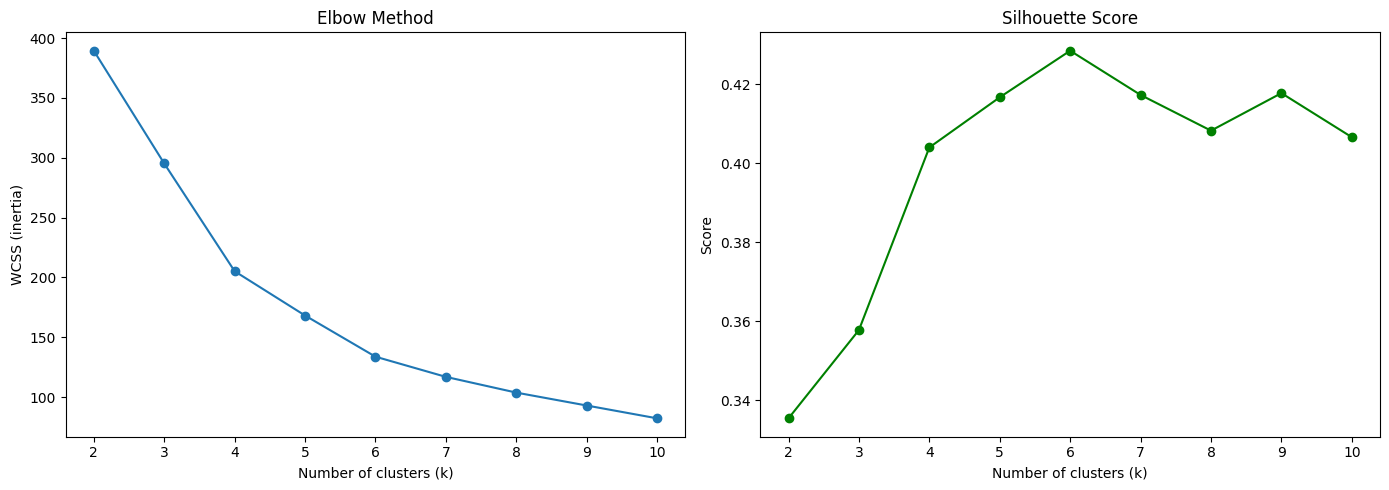

In [57]:
wcss=[]
sil_score=[]
k_range=range(2,11)
for k in k_range:
    km=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    km.fit(x_scaled_)
    wcss.append(km.inertia_)
    sil_score.append(silhouette_score(x_scaled_,km.labels_))

fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].plot(list(k_range),wcss,marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("WCSS (inertia)")

axes[1].plot(list(k_range),sil_score,marker='o',color='green')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

In [58]:
for k,s in zip(k_range,sil_score):
    print(f'k={k}: silhouette score={s:.4f}')

k=2: silhouette score=0.3355
k=3: silhouette score=0.3578
k=4: silhouette score=0.4040
k=5: silhouette score=0.4166
k=6: silhouette score=0.4284
k=7: silhouette score=0.4172
k=8: silhouette score=0.4082
k=9: silhouette score=0.4177
k=10: silhouette score=0.4066


- k=6 is chosen because it has the maximum silhouette score and the elbow point occurs at k=6

### 2.3 Fitting model with k=6

In [60]:
km=KMeans(n_clusters=6,init='k-means++',n_init=10,random_state=42)
df['Cluster1']=km.fit_predict(x_scaled_)
print('Silhouette score :',silhouette_score(x_scaled_,df['Cluster1']))
print(df['Cluster1'].value_counts().sort_index())

Silhouette score : 0.4284167762892593
Cluster1
0    45
1    39
2    33
3    39
4    23
5    21
Name: count, dtype: int64


### 2.4 Visualizing the clusters

In [61]:
pca=PCA(n_components=2,random_state=42)
x_pca_2d=pca.fit_transform(x_scaled_)
centroids_2d=pca.transform(km.cluster_centers_)

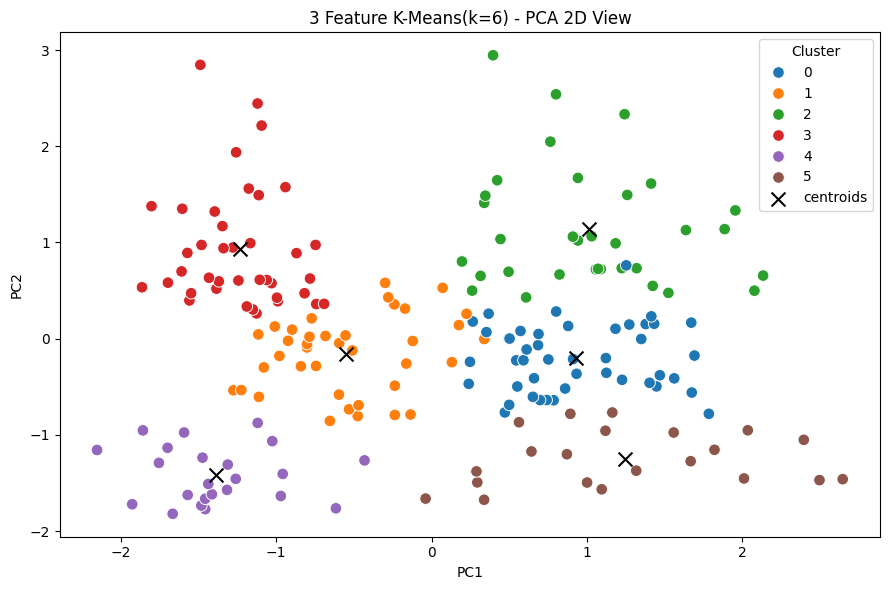

In [63]:
plt.figure(figsize=(9,6))
sns.scatterplot( x=x_pca_2d[:,0], y=x_pca_2d[:,1], hue=df['Cluster1'], palette='tab10',
                s=70,)
plt.scatter(centroids_2d[:,0],centroids_2d[:,1],s=100,c='black',marker='x',label='centroids',)
plt.title("3 Feature K-Means(k=6) - PCA 2D View")
plt.xlabel("PC1")
plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

### 2.5 Profile insights

In [90]:
profile1=df.groupby('Cluster1').agg(customers=('CustomerID','count'),
                                  avg_age=('Age','mean'),
                                  avg_income=('Annual Income (k$)','mean'),
                                  avg_spending=('Spending Score (1-100)','mean')

                                  ).round(1)
profile1

,customers,avg_age,avg_income,avg_spending
Cluster1,,,,
0,45,56.3,54.3,49.1
1,39,26.8,57.1,48.1
2,33,41.9,88.9,17.0
3,39,32.7,86.5,82.1
4,23,25.0,25.3,77.6
5,21,45.5,26.3,19.4


## 3. Selecting all the features 

In [72]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Cluster1
0,1,1,19,15,39,4,4
1,2,1,21,15,81,2,4
2,3,0,20,16,6,4,5
3,4,0,23,16,77,2,4
4,5,0,31,17,40,4,5


In [73]:
x=df.iloc[:,[1,2,3,4]]

In [74]:
x_scaled_all=scaler.fit_transform(x)

### Elbow method (WCSS) and silhouette score

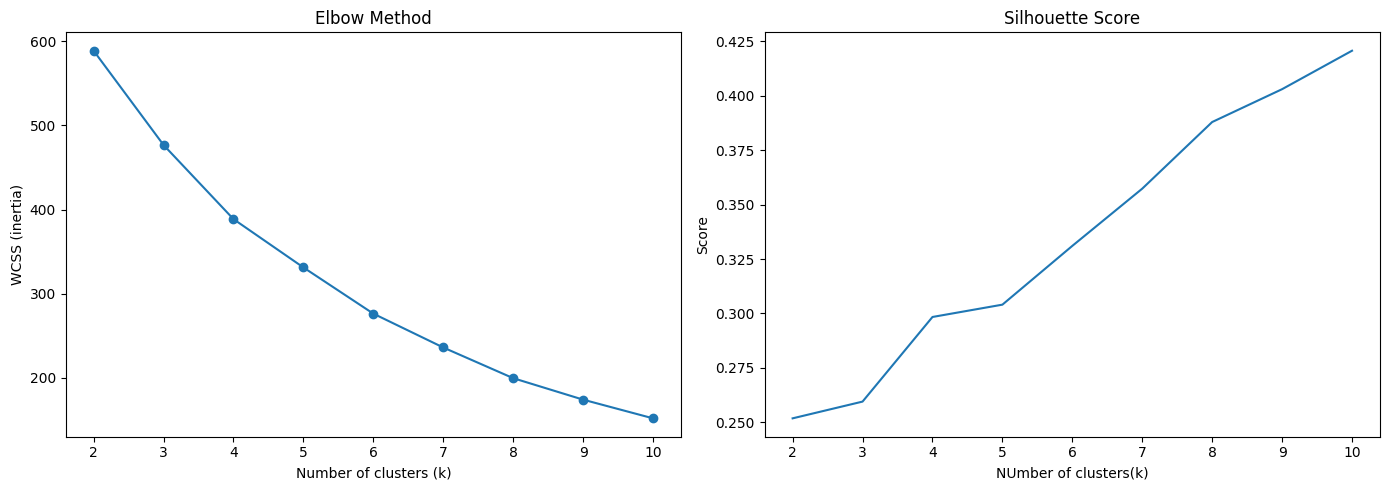

k=2 : silhouette scores=0.2518
k=3 : silhouette scores=0.2595
k=4 : silhouette scores=0.2984
k=5 : silhouette scores=0.3041
k=6 : silhouette scores=0.3311
k=7 : silhouette scores=0.3574
k=8 : silhouette scores=0.3880
k=9 : silhouette scores=0.4031
k=10 : silhouette scores=0.4208


In [76]:
wcss=[]
silh_scores=[]
k_range=range(2,11)

for k in k_range:
    km=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    km.fit(x_scaled_all)
    wcss.append(km.inertia_)
    silh_scores.append(silhouette_score(x_scaled_all,km.labels_))


fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].plot(list(k_range),wcss,marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('WCSS (inertia)')

axes[1].plot(list(k_range),silh_scores)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel('NUmber of clusters(k)')
axes[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

for k,s in zip(k_range,silh_scores):
    print(f'k={k} : silhouette scores={s:.4f}')


In [91]:
km = KMeans(n_clusters=10, n_init=10, random_state=42).fit(x_scaled_all)
pd.crosstab(km.labels_, df['Gender'])

Gender,0,1
row_0,,
0,0,26
1,0,24
2,13,1
3,21,0
4,26,0
5,0,19
6,25,0
7,0,18
8,13,0


- At k=10, 9 of 10 clusters contain only one gender (the tenth is 13 women, 1 man). The binary Gender feature dominates the distance calculation, so KMeans splits by gender first. This is why there is no clear elbow and the silhouette keeps rising. Gender is excluded from clustering in the next experiments and used only for profiling.

## 4. PCA before KMeans fitting with 3-features

In [77]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cluster,Cluster1
0,1,1,19,15,39,4,4
1,2,1,21,15,81,2,4
2,3,0,20,16,6,4,5
3,4,0,23,16,77,2,4
4,5,0,31,17,40,4,5


In [78]:
x=df.iloc[:,[2,3,4]]

In [79]:
x_scaled_=scaler.fit_transform(x)

In [84]:
pca=PCA(n_components=2,random_state=42)
x_pca=pca.fit_transform(x_scaled_)
print(f"Components kept: {pca.n_components_} |"
      f"Explained variance : {pca.explained_variance_ratio_.sum()*100:.1f}%")

Components kept: 2 |Explained variance : 77.6%


### Elbow method and silhouette score

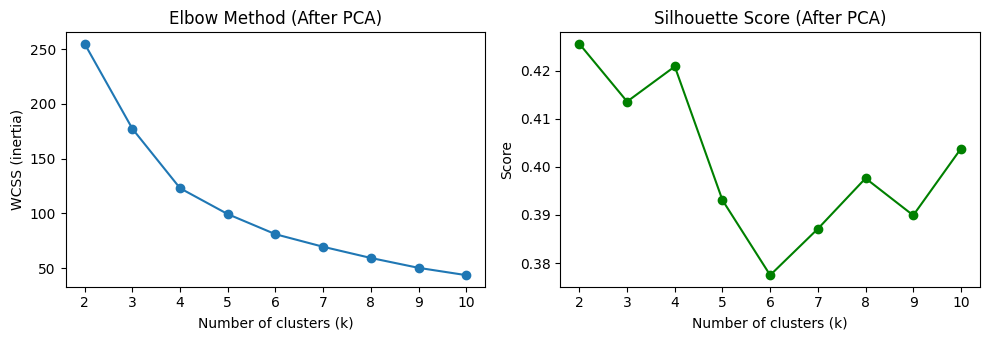

k=2  :  silhouette score=0.4256
k=3  :  silhouette score=0.4136
k=4  :  silhouette score=0.4209
k=5  :  silhouette score=0.3931
k=6  :  silhouette score=0.3775
k=7  :  silhouette score=0.3871
k=8  :  silhouette score=0.3976
k=9  :  silhouette score=0.3899
k=10  :  silhouette score=0.4038


In [85]:
wcss_pca=[]
sil_pca=[]
k_range=range(2,11)

for k in k_range:
    km=KMeans(n_clusters=k,init='k-means++',n_init=10,random_state=42)
    labels=km.fit_predict(x_pca)
    wcss_pca.append(km.inertia_)
    sil_pca.append(silhouette_score(x_pca,labels))

fig,ax=plt.subplots(1,2,figsize=(10,3.5))

ax[0].plot(list(k_range),wcss_pca,marker='o')
ax[0].set_title('Elbow Method (After PCA)')
ax[0].set_xlabel('Number of clusters (k)')
ax[0].set_ylabel('WCSS (inertia)')

ax[1].plot(list(k_range),sil_pca,marker='o',color='green')
ax[1].set_title('Silhouette Score (After PCA)')
ax[1].set_xlabel('Number of clusters (k)')
ax[1].set_ylabel('Score')

plt.tight_layout()
plt.show()

for k,s in zip(k_range,sil_pca):
    print(f"k={k}  :  silhouette score={s:.4f}")

In [86]:
best_k_pca=4
km_pca=KMeans(n_clusters=4,init='k-means++',n_init=10,random_state=42)
df['Cluster_pca']=km_pca.fit_predict(x_pca)
print(f'Silhouette score (k={best_k_pca}) :'
      f'{silhouette_score(x_pca,df['Cluster_pca']):.4f}')
print(df['Cluster_pca'].value_counts().sort_index())

Silhouette score (k=4) :0.4209
Cluster_pca
0    69
1    58
2    38
3    35
Name: count, dtype: int64


### Visualizaton

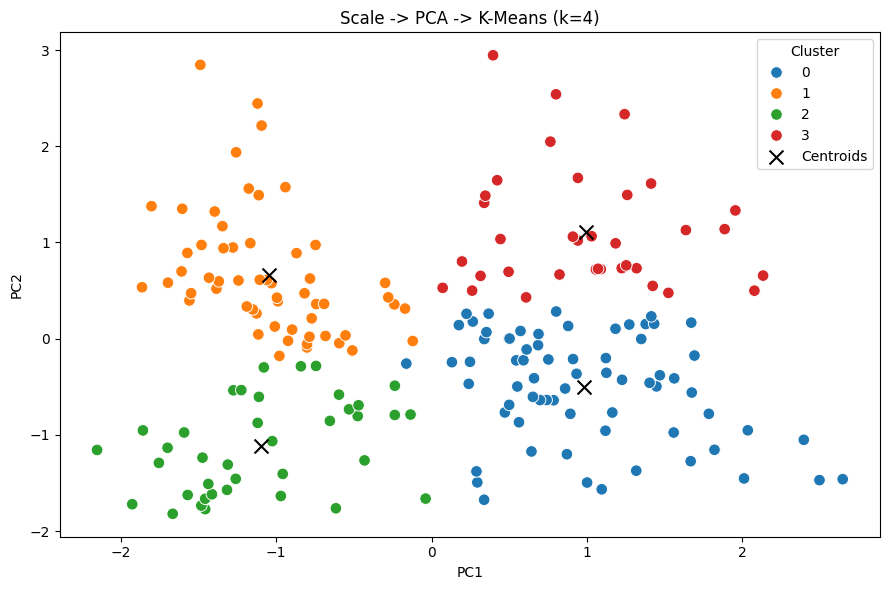

In [88]:
plt.figure(figsize=(9,6))
sns.scatterplot(x=x_pca[:,0],
                y=x_pca[:,1],
                hue=df['Cluster_pca'],
                palette='tab10',
                s=70,)
plt.scatter(km_pca.cluster_centers_[:,0],
            km_pca.cluster_centers_[:,1],
            s=100, c='black',marker='x', label='Centroids',
            )
plt.title(f'Scale -> PCA -> K-Means (k={best_k_pca})')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

In [89]:
profile_pca=df.groupby('Cluster_pca').agg(customers=('CustomerID','count'),
                                  avg_age=('Age','mean'),
                                  avg_income=('Annual Income (k$)','mean'),
                                  avg_spending=('Spending Score (1-100)','mean')

                                  ).round(1)
profile_pca

,customers,avg_age,avg_income,avg_spending
Cluster_pca,,,,
0,69,52.1,46.3,40.1
1,58,30.0,79.1,70.8
2,38,25.6,32.6,67.5
3,35,41.7,88.2,17.3
